[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yulangrichard/Nagyhazi_Sordinger/blob/main/nagyhazi_sordinger_milestone1.ipynb)

In [6]:
import os
import zipfile
import requests

file_id = "14YThra4ZHtyP5d__puQYFArvyZyUaqY8"
output_zip = "dataset.zip"

print("Downloading from Google Drive (with security confirmation)...")

# Direct download URL required by Google Drive for large files
URL = "https://drive.usercontent.google.com/download"

session = requests.Session()

# Based on the HTML form, the server expects exactly these parameters
params = {
    'id': file_id,
    'export': 'download',
    'confirm': 't',
    'uuid': '449d788e-6e00-461e-8e85-911c32e6aedb'
}

response = session.get(URL, params=params, stream=True)

# Write the file to disk chunk by chunk
with open(output_zip, "wb") as f:
    for chunk in response.iter_content(chunk_size=32768):
        if chunk:
            f.write(chunk)

print("Download complete! Extracting...")

# Extract into the 'data' folder
os.makedirs("data", exist_ok=True)
with zipfile.ZipFile(output_zip, 'r') as zip_ref:
    zip_ref.extractall("data")

print("Data successfully placed into the 'data' folder!")

Download complete! Extracting...
Data successfully placed into the 'data' folder!


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
from keras import layers
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)
print("Keras version:     ", keras.__version__)


TensorFlow version: 2.21.0
Keras version:      3.13.2


In [8]:
SEED = 42
IMG_SIZE = (224, 448)
BATCH_SIZE = 32

EPOCHS_BASELINE = 150
EPOCHS_FEATURE = 100
EPOCHS_FINETUNE = 100

LR_FEATURE = 1e-3
LR_FINETUNE = 1e-5
FINE_TUNE_AT = 100

TRAIN_SPLIT = 70
VAL_SPLIT = 20
# though there is a test folder included in the downloaded competition dataset, it only includes 1 image, therefore i used a section of the training data for the testing
TEST_SPLIT = 10

keras.utils.set_random_seed(SEED)

In [9]:
path = "data/dataset"

# Load dataset and pivot from long format to wide format so each image has one row
# with multiple target values corresponding to different biomass components.

df = pd.read_csv(path + "/train.csv")
df = df.pivot_table(
    index="image_path",
    values="target",
    columns="target_name"
).reset_index()

# Define biomass target categories for regression

target_cols = ['Dry_Green_g', 'Dry_Dead_g', 'Dry_Clover_g', 'GDM_g', 'Dry_Total_g']

# Prepare file paths and target values as NumPy arrays

image_paths = (path + "/" + df["image_path"]).values
y = df[target_cols].values.astype(np.float32)

# Partition the dataset into training, validation, and test sets sequentially
# based on predefined split percentages.
train_paths, y_train = (
    image_paths[: int(len(image_paths) * TRAIN_SPLIT / 100)],
    y[: int(len(y) * TRAIN_SPLIT / 100)],
)
val_paths, y_val = (
    image_paths[int(len(image_paths) * TRAIN_SPLIT / 100): int(len(image_paths) * (TRAIN_SPLIT + VAL_SPLIT) / 100)],
    y[int(len(y) * TRAIN_SPLIT / 100): int(len(y) * (TRAIN_SPLIT + VAL_SPLIT) / 100)],
)
test_paths, y_test = image_paths[int(len(image_paths) * (TRAIN_SPLIT + VAL_SPLIT) / 100):], y[int(len(y) * (TRAIN_SPLIT + VAL_SPLIT) / 100):]


# 2. Define a TensorFlow preprocessing function to load, decode, resize, and normalize images
def load_and_resize(file_path, label):
    img_bytes = tf.io.read_file(file_path)
    img = tf.image.decode_image(
        img_bytes, channels=3, expand_animations=False
    )
    img = tf.image.resize(img, IMG_SIZE)
    img = img / 255.0  # Scale to 0-1
    return img, label


AUTOTUNE = tf.data.AUTOTUNE
# Define data augmentation pipeline to improve generalization and prevent overfitting
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),    # ±10% rotation
    layers.RandomZoom(0.1),        # ±10% zoom
], name="adatbovites")

# Wrapper function to apply data augmentation to training samples
def augment(image, label):
    return data_augmentation(image, training=True), label


# Build optimized tf.data pipelines for efficient data loading and GPU utilization
# --- TRAINING DATASET (includes preprocessing, caching, augmentation, and shuffling) ---
train_ds = (
    tf.data.Dataset.from_tensor_slices((train_paths, y_train))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(1000, seed=SEED)
    .map(augment, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# --- VALIDATION DATASET ---
val_ds = (
    tf.data.Dataset.from_tensor_slices((val_paths, y_val))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# --- TEST DATASET ---
test_ds = (
    tf.data.Dataset.from_tensor_slices((test_paths, y_test))
    .map(load_and_resize, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Inspect the shape of a single generated batch to verify pipeline correctness
for images, labels in train_ds.take(1):
    print("Shape of pictures in a batch:", images.shape)
    print("Shape of labels in a batch:", labels.shape)



Shape of pictures in a batch: (32, 244, 448, 3)
Shape of labels in a batch: (32, 5)


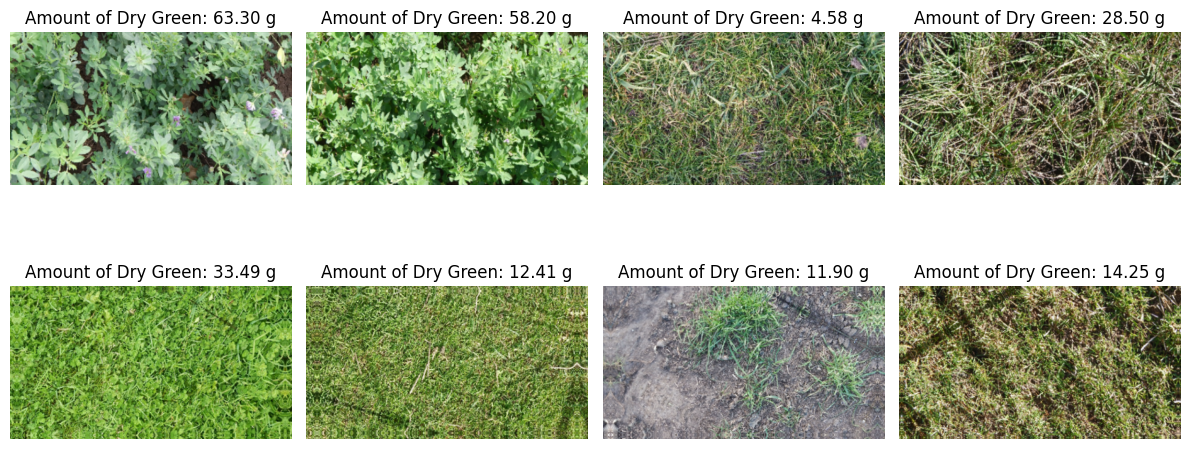

In [10]:
import matplotlib.pyplot as plt

# Extract a single batch of images and labels from the training dataset pipeline
# to visualize the augmented data.

for images, labels in train_ds.take(1):
    batch_images = images.numpy()
    batch_labels = labels.numpy()
    break

# Set up a grid layout to display multiple sample images from the batch

plt.figure(figsize=(12, 6))
for i in range(min(8, len(batch_images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(batch_images[i])
    # Display the corresponding target value for 'Dry_Green_g' (index 0) in the title
    plt.title(f"Amount of Dry Green: {batch_labels[i][0]:.2f} g")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# 5. BASELINE MODEL — small CNN trained from scratch
# ============================================================
def build_baseline_cnn():
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(target_cols), name="biomass")(x)

    return keras.Model(inputs, outputs, name="baseline_cnn")


baseline = build_baseline_cnn()
baseline.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.Huber(),                       # robust to outliers, better than MSE here
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)
baseline.summary()

callbacks_baseline = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=8, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint("baseline_best.keras", monitor="val_loss",
                                    save_best_only=True, verbose=1),
]

history_baseline = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_BASELINE,
    callbacks=callbacks_baseline,
)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 244, 448, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 244, 448, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 244, 448, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 122, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 122, 224, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 122, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 61, 112, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 61, 112, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 61, 112, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 30, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 30, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ biomass (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 23.1446 - mae: 23.6200   
Epoch 1: val_loss improved from None to 26.07599, saving model to baseline_best.keras

Epoch 1: finished saving model to baseline_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 62s 5s/step - loss: 23.1718 - mae: 23.6472 - val_loss: 26.0760 - val_mae: 26.5172 - learning_rate: 0.0010
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - loss: 21.3955 - mae: 21.8752
Epoch 2: val_loss improved from 26.07599 to 25.58046, saving model to baseline_best.keras

Epoch 2: finished saving model to baseline_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 28s 708ms/step - loss: 20.9538 - mae: 21.4327 - val_loss: 25.5805 - val_mae: 26.0415 - learning_rate: 0.0010
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 750ms/step - loss: 19.1025 - mae: 19.5858
Epoch 3: val_loss improved from 25.58046 to 24.98159, saving model to baseline_best.keras

Epoch 3: finished saving model to baseline_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 805ms/step - loss: 19.0400 - m

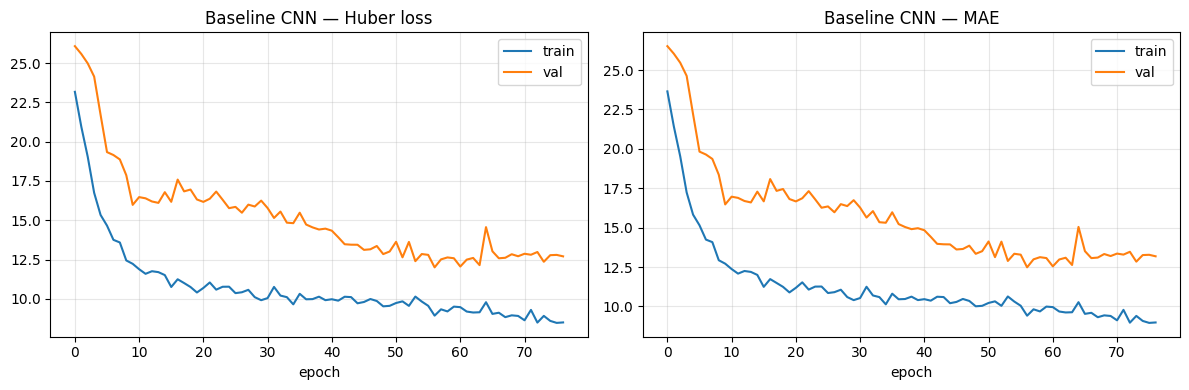


=== Baseline CNN (test) ===
Overall (mean-of-targets) MAE: 9.890 g


,target,MAE (g),R²
0,Dry_Green_g,11.679,0.260
1,Dry_Dead_g,6.533,-0.235
2,Dry_Clover_g,7.232,-0.035
3,GDM_g,11.663,0.257
4,Dry_Total_g,12.345,0.156


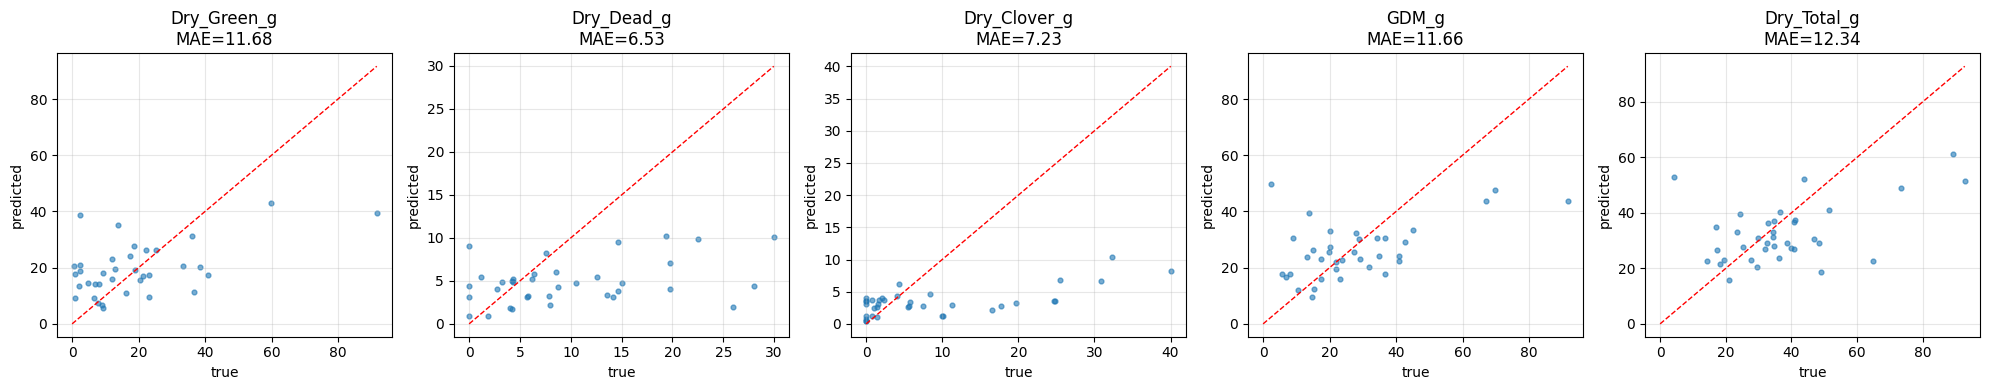

In [12]:
# ============================================================
# 6. EVALUATION HELPERS
# ============================================================
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title(f"{title} — Huber loss")
    axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

    axes[1].plot(history.history["mae"], label="train")
    axes[1].plot(history.history["val_mae"], label="val")
    axes[1].set_title(f"{title} — MAE")
    axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()


def evaluate_model(model, ds, y_true, title="Model"):
    """Predict on a tf.data pipeline and report per-target MAE / R² + scatter plots."""
    y_pred = model.predict(ds, verbose=0)
    y_pred = np.clip(y_pred, 0, None)                # biomass cannot be negative

    mae_per_target = np.abs(y_pred - y_true).mean(axis=0)
    overall_mae = mae_per_target.mean()

    ss_res = ((y_true - y_pred) ** 2).sum(axis=0)
    ss_tot = ((y_true - y_true.mean(axis=0)) ** 2).sum(axis=0)
    r2_per_target = 1 - ss_res / ss_tot

    print(f"\n=== {title} ===")
    print(f"Overall (mean-of-targets) MAE: {overall_mae:.3f} g")
    display(pd.DataFrame({
        "target": target_cols,
        "MAE (g)": mae_per_target.round(3),
        "R²": r2_per_target.round(3),
    }))

    fig, axes = plt.subplots(1, len(target_cols), figsize=(4 * len(target_cols), 4))
    for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), target_cols)):
        ax.scatter(y_true[:, i], y_pred[:, i], s=12, alpha=0.6)
        hi = max(y_true[:, i].max(), y_pred[:, i].max())
        ax.plot([0, hi], [0, hi], "r--", lw=1)
        ax.set_title(f"{name}\nMAE={mae_per_target[i]:.2f}")
        ax.set_xlabel("true"); ax.set_ylabel("predicted"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

    return y_pred, overall_mae


plot_history(history_baseline, "Baseline CNN")
pred_base, mae_base = evaluate_model(baseline, test_ds, y_test, "Baseline CNN (test)")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 244, 448, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 14, 1280)    │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ biomass (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 23.6950 - mae: 24.1732   
Epoch 1: val_loss improved from None to 23.80577, saving model to feature_extraction_best.keras

Epoch 1: finished saving model to feature_extraction_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 141s 11s/step - loss: 23.1071 - mae: 23.5898 - val_loss: 23.8058 - val_mae: 24.2880 - learning_rate: 0.0010
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 558ms/step - loss: 19.8661 - mae: 20.3497
Epoch 2: val_loss improved from 23.80577 to 20.97193, saving model to feature_extraction_best.keras

Epoch 2: finished saving model to feature_extraction_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 724ms/step - loss: 19.8421 - mae: 20.3274 - val_loss: 20.9719 - val_mae: 21.4411 - learning_rate: 0.0010
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 674ms/step - loss: 17.3018 - mae: 17.7877
Epoch 3: val_loss improved from 20.97193 to 18.37072, saving model to feature_extraction_best.keras

Epoch 3: finished saving model to feature_extraction_best.ker

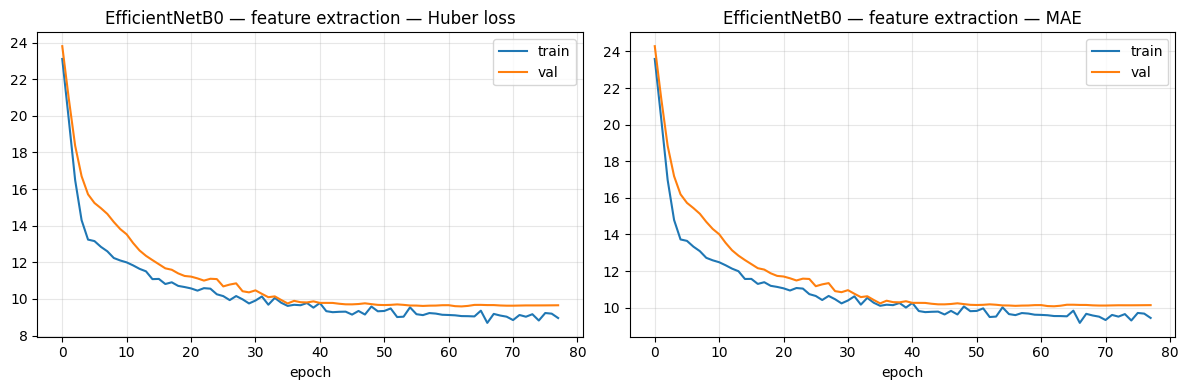


=== EfficientNetB0 (frozen, test) ===
Overall (mean-of-targets) MAE: 7.954 g


,target,MAE (g),R²
0,Dry_Green_g,9.000,0.522
1,Dry_Dead_g,5.895,-0.140
2,Dry_Clover_g,5.997,0.186
3,GDM_g,9.298,0.544
4,Dry_Total_g,9.579,0.560


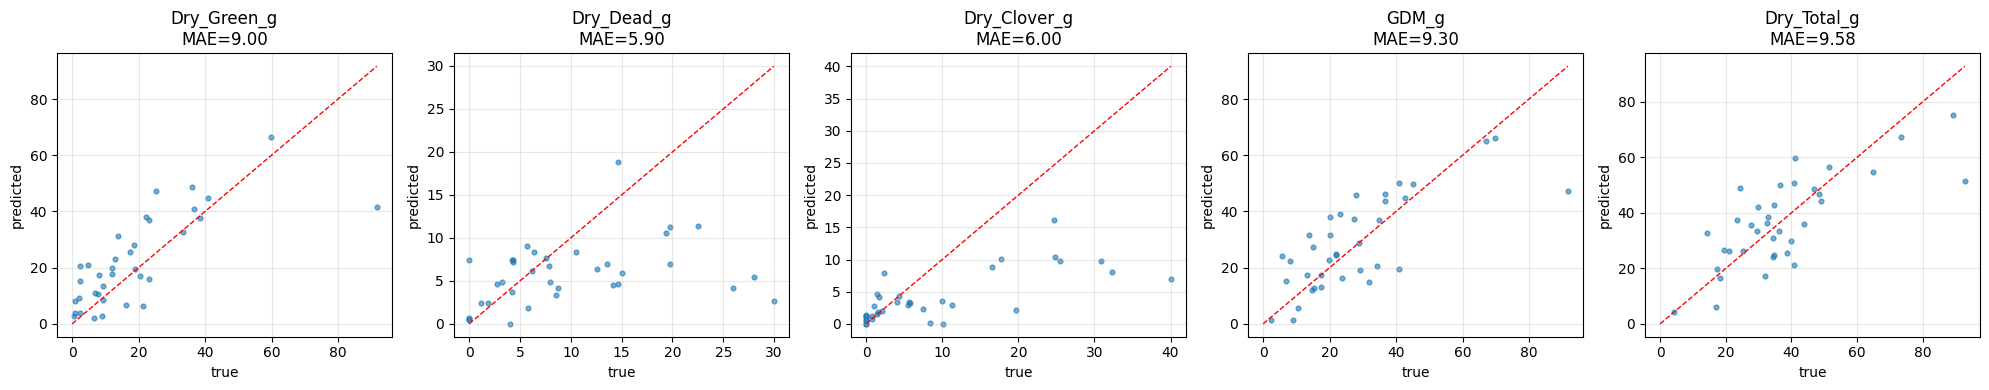

In [15]:
# ============================================================
# 7. TRANSFER LEARNING — feature extraction with EfficientNetB0
# ============================================================
def make_datasets(preprocess_fn):
    def load_fn(file_path, label):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, IMG_SIZE)
        return preprocess_fn(img), label

    tr = (tf.data.Dataset.from_tensor_slices((train_paths, y_train))
          .map(load_fn, num_parallel_calls=AUTOTUNE)
          .cache()
          .shuffle(1000, seed=SEED)
          .map(augment, num_parallel_calls=AUTOTUNE)   # augment AFTER cache (see note below)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

    va = (tf.data.Dataset.from_tensor_slices((val_paths, y_val))
          .map(load_fn, num_parallel_calls=AUTOTUNE)
          .cache().batch(BATCH_SIZE).prefetch(AUTOTUNE))

    te = (tf.data.Dataset.from_tensor_slices((test_paths, y_test))
          .map(load_fn, num_parallel_calls=AUTOTUNE)
          .cache().batch(BATCH_SIZE).prefetch(AUTOTUNE))
    return tr, va, te


def keep_0_255(img):
    return img                       # EfficientNet handles normalisation internally

tl_train, tl_val, tl_test = make_datasets(keep_0_255)

# --- backbone ---
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
)
base_model.trainable = False       # stage 1: freeze

inputs  = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x       = base_model(inputs, training=False)      # keep BN in inference mode
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
x       = layers.Dense(128, activation="relu")(x)
x       = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(target_cols), name="biomass")(x)

model_tl = keras.Model(inputs, outputs, name="efficientnetb0_regressor")
model_tl.compile(
    optimizer=keras.optimizers.Adam(LR_FEATURE),
    loss=keras.losses.Huber(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)
model_tl.summary()

callbacks_fe = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                      patience=6, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint("feature_extraction_best.keras",
                                    monitor="val_loss", save_best_only=True, verbose=1),
]

history_fe = model_tl.fit(
    tl_train, validation_data=tl_val,
    epochs=EPOCHS_FEATURE, callbacks=callbacks_fe,
)

plot_history(history_fe, "EfficientNetB0 — feature extraction")
pred_fe, mae_fe = evaluate_model(model_tl, tl_test, y_test, "EfficientNetB0 (frozen, test)")

Trainable parameters after unfreezing: 3,968,897
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 8.7290 - mae: 9.2034   
Epoch 1: val_loss improved from None to 9.63452, saving model to finetuned_best.keras

Epoch 1: finished saving model to finetuned_best.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 104s 7s/step - loss: 8.7913 - mae: 9.2668 - val_loss: 9.6345 - val_mae: 10.1159 - learning_rate: 1.0000e-05
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - loss: 9.6773 - mae: 10.1558
Epoch 2: val_loss did not improve from 9.63452
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 826ms/step - loss: 9.2694 - mae: 9.7471 - val_loss: 9.6695 - val_mae: 10.1526 - learning_rate: 1.0000e-05
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - loss: 9.2025 - mae: 9.6825
Epoch 3: val_loss did not improve from 9.63452
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 632ms/step - loss: 8.5428 - mae: 9.0214 - val_loss: 9.7437 - val_mae: 10.2242 - learning_rate: 1.0000e-05
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 679ms/step - loss: 9.4218 - mae: 

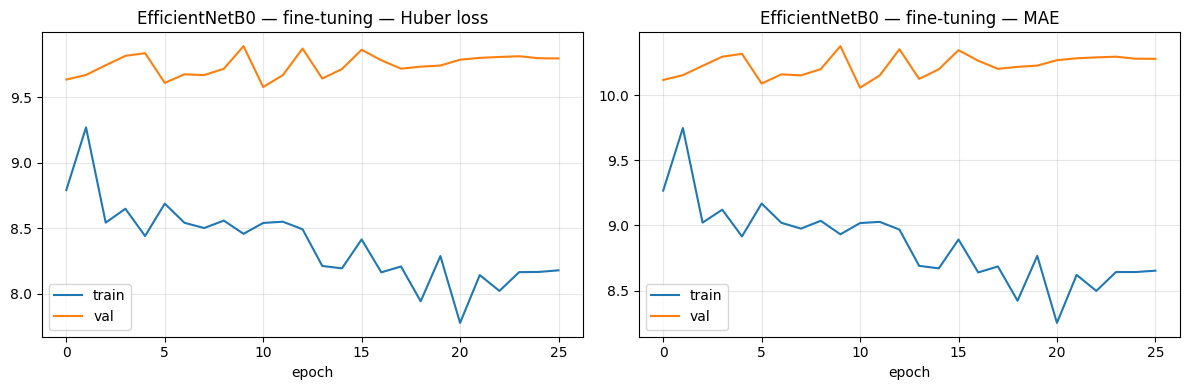


=== EfficientNetB0 (fine-tuned, test) ===
Overall (mean-of-targets) MAE: 8.130 g


,target,MAE (g),R²
0,Dry_Green_g,9.294,0.524
1,Dry_Dead_g,6.115,-0.216
2,Dry_Clover_g,5.824,0.208
3,GDM_g,9.542,0.563
4,Dry_Total_g,9.876,0.551


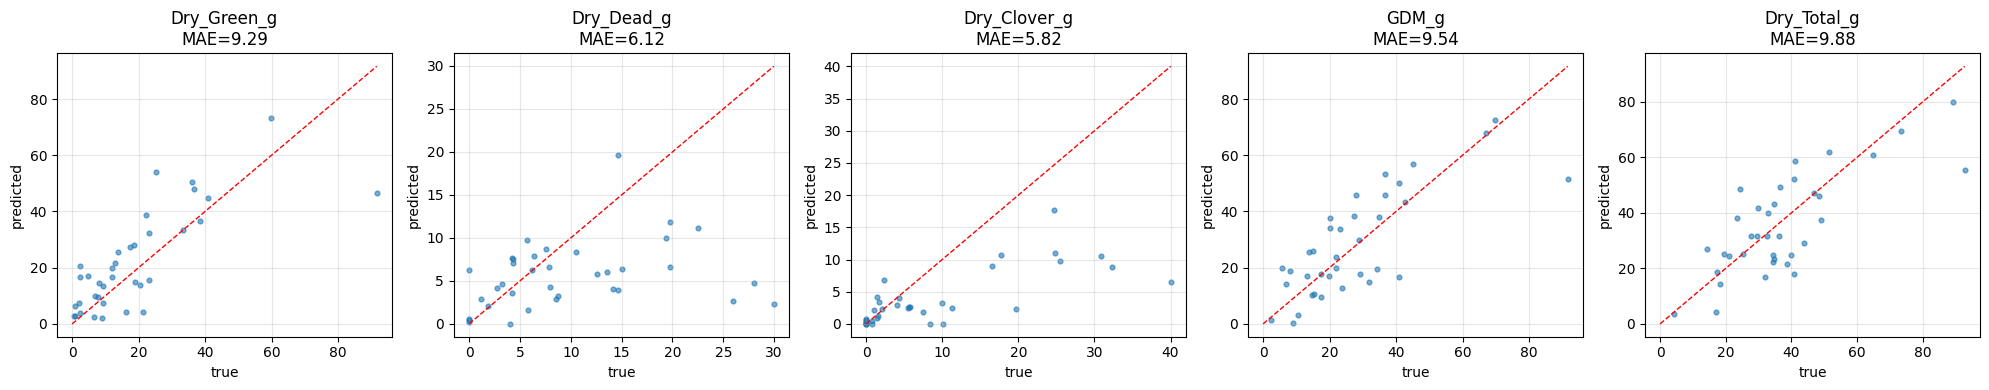

In [16]:
# ============================================================
# 8. FINE-TUNING — unfreeze top of the backbone, very small LR
# ============================================================
base_model.trainable = True

# freeze everything below FINE_TUNE_AT, keep BN layers frozen in all cases
for i, layer in enumerate(base_model.layers):
    if i < FINE_TUNE_AT or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_count = sum(int(tf.size(w)) for w in model_tl.trainable_weights)
print(f"Trainable parameters after unfreezing: {trainable_count:,}")

model_tl.compile(
    optimizer=keras.optimizers.Adam(LR_FINETUNE),   # 1e-5 — do NOT use 1e-3 here
    loss=keras.losses.Huber(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

callbacks_ft = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                      patience=5, min_lr=1e-8, verbose=1),
    keras.callbacks.ModelCheckpoint("finetuned_best.keras",
                                    monitor="val_loss", save_best_only=True, verbose=1),
]

history_ft = model_tl.fit(
    tl_train, validation_data=tl_val,
    epochs=EPOCHS_FINETUNE, callbacks=callbacks_ft,
)

plot_history(history_ft, "EfficientNetB0 — fine-tuning")
pred_ft, mae_ft = evaluate_model(model_tl, tl_test, y_test, "EfficientNetB0 (fine-tuned, test)")

,Model,Test MAE (g)
1,EfficientNetB0 (frozen),7.953879
2,EfficientNetB0 (fine-tuned),8.130190
0,Baseline CNN,9.890387


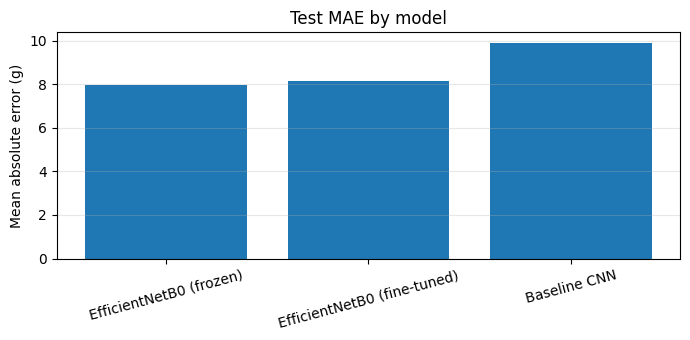

In [17]:
# ============================================================
# 9. FINAL COMPARISON
# ============================================================
comparison = pd.DataFrame({
    "Model": ["Baseline CNN", "EfficientNetB0 (frozen)", "EfficientNetB0 (fine-tuned)"],
    "Test MAE (g)": [mae_base, mae_fe, mae_ft],
}).sort_values("Test MAE (g)")
display(comparison)

plt.figure(figsize=(7, 3.5))
plt.bar(comparison["Model"], comparison["Test MAE (g)"])
plt.ylabel("Mean absolute error (g)"); plt.title("Test MAE by model")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

model_tl.save("final_efficientnet_model.keras")